# DocuFlow, explained — a document from arrival to posted record

A photograph of an invoice goes in. A checked accounting record comes out, or a
person is asked to look at it. This notebook follows **one document through
every stage** and prints what each stage received and what it produced, so the
architecture is visible rather than described.

## The one sentence version

> **The model reads. The code decides.**

Everything else follows from that split. A language model is good at finding the
total on a page it has never seen before, and it is the wrong thing to ask
whether an invoice may be paid — it can be talked out of the answer by the
document itself. So models extract, and only code routes.

## The map

```
  ┌────────┐   ┌───────┐   ┌─────┐   ┌──────────┐
  │ render │──▶│ clean │──▶│ OCR │──▶│ classify │
  └────────┘   └───────┘   └─────┘   └──────────┘
   file → page   measure,    page →    which kind
     images      fix, and     text     of document
                 re-measure                 │
                                            ▼
        ┌──────────────── read it twice ─────────────────┐
        │  channel A: Typhoon      channel B: Claude     │
        │  field-first             label-first           │
        └───────────────────────┬───────────────────────┘
                                ▼
                      ┌───────────────────┐
                      │  merge  +  ground │   do they agree, and is
                      └───────────────────┘   every value on the page?
                                ▼
                      ┌───────────────────┐
                      │       rules       │   arithmetic, master data,
                      └───────────────────┘   your own checks
                                ▼
                      ┌───────────────────┐
                      │       route       │   post, or hand to a person
                      └───────────────────┘
```

| Stage | The question it answers | Answered by |
|---|---|---|
| render | what does each page look like? | code |
| clean | is the page legible, and can it be made more so? | code |
| OCR | what characters are on it? | Typhoon OCR 1.5 |
| classify | invoice, receipt, contract or form? | keywords; a model only if they are close |
| read A | where are the fields? | Typhoon |
| read B | same question, different model, no shared prompt | Claude |
| merge | do the two agree, and can each value be found on the page? | code |
| rules | does the document hold up against arithmetic and the master files? | code (plus tools, for the checks a comparison cannot express) |
| route | post it, or stop it? | **code, always** |

## Two ideas worth holding on to before you start

**Two readings, two different backends.** One model reporting a number is a
claim; two models that never saw each other's answer agreeing is evidence. On
the project corpus, fields both channels agree on are right 97% of the time;
fields they disagree on, 45%. That gap is the point — the system knows which of
its own answers to distrust. Two passes of the *same* model would not give you
this: it repeats its own mistake and the agreement means nothing.

**Grounding.** Every value must be quoted from a span of text that is actually on
the page. A value the model produced but the page does not contain is treated as
invented, and never posts on its own however confident the model sounded.

---

*Companion notebook:* `docuflow_walkthrough.ipynb` runs the same pipeline against
the full production rule set with every option spelled out. This one is the
explanation; that one is the reference.

## Part 0 — Setup

**A Colab runtime is a blank machine, and it is thrown away when it
disconnects.** Not just idle — disconnected. Everything below is here because of
that: the code, the package, the keys and the database all live on a VM that
will not exist tomorrow, and quite possibly not in an hour.

So Part 0 is "turn a blank machine into one that can run this". Four steps:

| | |
|---|---|
| **get the code** | Option A *or* B — **not both** |
| **install it** | the package and its dependencies |
| **keys** | put them in Colab's 🔑 panel once and this stops asking |
| **configure** | thresholds, VAT rates, master data |

If you come back to a disconnected runtime, run the **status cell** below — it
tells you what survived and what to re-run, which is faster than finding out
from an exception six cells later.

### Get the code — pick **one** of the next two cells

The repository is private, so either give Colab a token, or hand it a zip.
Whichever you skip is harmless: both cells check whether the code is already
there and do nothing if it is.

In [ ]:
# --- Option A: clone with a GitHub token ----------------------------------
# Read with getpass, so it is never printed into the notebook or saved with it.
# Make one at https://github.com/settings/tokens with `repo` scope.
#
# Prefer not to make a token? Skip this cell entirely and run Option B.
import getpass, os, subprocess, sys

REPO = "tententgc/mirtphol_doc_extraction"

if os.path.exists("mirtphol_doc_extraction"):
    print("the code is already here — nothing to do, and Option B is unnecessary too")
else:
    token = getpass.getpass(f"GitHub token for {REPO} (blank to skip): ").strip()
    if token:
        subprocess.run(["git", "clone", "--depth", "1",
                        f"https://{token}@github.com/{REPO}.git"], check=True)
        del token
        print("cloned — skip Option B, go straight to the install")
    else:
        print("skipped — use Option B below instead")

In [ ]:
# --- Option B: upload a zip instead ---------------------------------------
# Only if you skipped Option A.
#   on your machine:  git archive -o docuflow.zip HEAD
import os

if os.path.exists("mirtphol_doc_extraction"):
    print("the code is already here — Option A did its job, nothing to upload")
else:
    import zipfile
    from google.colab import files          # noqa: F401 - Colab only
    uploaded = files.upload()
    name = next(iter(uploaded))
    os.makedirs("mirtphol_doc_extraction", exist_ok=True)
    with zipfile.ZipFile(name) as archive:
        archive.extractall("mirtphol_doc_extraction")
    print("extracted to mirtphol_doc_extraction/")

In [ ]:
%pip install -q -e "mirtphol_doc_extraction[claude]"
print("installed")

### Keys

Two, and the second one matters more than it looks. `TYPHOON_API_KEY` runs the
OCR and the first reading. `ANTHROPIC_API_KEY` runs the *second* reading, and
without it the second channel falls back to a deterministic label matcher —
which still works, but you lose the two-independent-models comparison that this
notebook spends a whole stage on.

**Put them in the 🔑 panel on the left, not in this cell.** Click the key icon,
add `TYPHOON_API_KEY` and `ANTHROPIC_API_KEY`, and switch on *Notebook access*
for each. They then live in your Google account rather than on the VM, so a
disconnect costs you nothing and the cell below stops asking. Typing them in
survives exactly one runtime.

Nothing here writes a key into the notebook, either way.

In [ ]:
import getpass, os

def read_key(name, required):
    """From Colab's secret store if it is there, otherwise ask once.

    The 🔑 panel keeps a value in your Google account instead of on the VM,
    which is the difference between setting a key once and retyping it after
    every disconnect. Everything else here is a fallback for running outside
    Colab, or before the secret has been added.
    """
    if os.environ.get(name):
        return os.environ[name], "already in this session"
    try:
        from google.colab import userdata
    except ImportError:
        pass                                    # not Colab; ask below
    else:
        try:
            value = (userdata.get(name) or "").strip()
            if value:
                return value, "from the 🔑 panel"
        except Exception as exc:                # not added, or access not granted
            print(f"   {name}: {type(exc).__name__} — add it in the 🔑 panel and "
                  f"switch on Notebook access to stop being asked")
    prompt = f"{name}: " if required else f"{name} (optional, press Enter to skip): "
    return getpass.getpass(prompt).strip(), "typed in, and gone when this runtime is"

for name, required in (("TYPHOON_API_KEY", True), ("ANTHROPIC_API_KEY", False)):
    os.environ[name], where = read_key(name, required)
    if os.environ[name]:
        print(f"{name:18} {where}")
    elif required:
        print(f"{name:18} MISSING — nothing below will run")
    else:
        print(f"{name:18} not set — the second reading will be the deterministic matcher")

### Is this runtime still set up?

Run this whenever you come back to the notebook. Colab discards a runtime on
disconnect, and the failure that follows is a `ModuleNotFoundError` eight cells
later that says nothing about which step went missing.

In [5]:
import importlib.util, os
from pathlib import Path

def ready():
    have_code = Path("mirtphol_doc_extraction").exists() or Path("src/docuflow").exists()
    checks = [
        ("the code",     have_code,                                        "Option A or B"),
        ("the package",  importlib.util.find_spec("docuflow") is not None, "the %pip cell"),
        ("Typhoon key",  bool(os.environ.get("TYPHOON_API_KEY")),          "the keys cell"),
    ]
    optional = [("Claude key", bool(os.environ.get("ANTHROPIC_API_KEY")), "the keys cell")]

    for label, ok, where in checks:
        print(f"  {'ok  ' if ok else 'MISSING'}  {label:14} {'' if ok else f'← re-run {where}'}")
    for label, ok, where in optional:
        print(f"  {'ok  ' if ok else 'absent '}  {label:14} "
              f"{'' if ok else '← optional; the second reading falls back without it'}")

    missing = [where for _, ok, where in checks if not ok]
    print()
    if missing:
        print(f"Not ready. Re-run: {', '.join(dict.fromkeys(missing))}.")
    else:
        print("Ready — everything below can run.")
    return not missing

ready()

  ok    the code       
  ok    the package    
  ok    Typhoon key    
  ok    Claude key     

Ready — everything below can run.


True

### Configuration

Every setting below is a **business** decision rather than a technical one, which
is why they are written out here instead of left to a default. Someone in finance
should be able to read this cell and disagree with it.

The one to notice is `auto_post_min_confidence`. Confidence answers exactly one
question — *did we read the values correctly* — and the threshold is where you
put the line between "post this" and "a person should look".

In [ ]:
import os
from pathlib import Path
from docuflow.config import Settings
from docuflow.bootstrap import bootstrap

WORK = Path("/content/docuflow-explained") if Path("/content").exists() else Path("./docuflow-explained")

settings = Settings(
    data_dir=WORK,
    # --- reading the page --------------------------------------------------
    ocr_provider="typhoon_api",
    ocr_cloud_model="typhoon-ocr-v1.5",
    ocr_max_pages=4,
    # --- channel A ---------------------------------------------------------
    llm_provider="typhoon",
    llm_cloud_model="typhoon-v2.5-30b-a3b-instruct",
    # --- channel B: a different backend, on purpose ------------------------
    llm_verify_provider="claude" if os.environ.get("ANTHROPIC_API_KEY") else "auto",
    llm_anthropic_model="claude-sonnet-5",
    llm_verify_timeout_seconds=120,
    # --- keys --------------------------------------------------------------
    typhoon_api_key=os.environ.get("TYPHOON_API_KEY", ""),
    anthropic_api_key=os.environ.get("ANTHROPIC_API_KEY", ""),
    # --- business policy ---------------------------------------------------
    auto_post_min_confidence=0.84,   # below this, a person looks at it
    po_required_above=50_000,        # baht, above which an invoice must quote a PO
    expected_vat_rates="0,7",        # Thailand is 7%
    amount_tolerance=0.02,           # how far an invoice may differ from its PO
    # --- which rules run ---------------------------------------------------
    # Pinned, and this is not a formality. `Settings` reads any field it was not
    # given from a `.env` sitting in the working directory, so a notebook that
    # states its thresholds but says nothing about its rule set quietly runs
    # whichever checks that machine happens to have switched off — and prints
    # the results as though they described the system. Stating it here makes
    # every stage below a statement about the code.
    rules_free_mode=False,
    builtin_rules_disabled=False,
    disabled_rules="",
    # Master data comes from the CSVs two cells down, the way an ERP export
    # would arrive. Nothing is invented here.
    seed_demo_master_data=False,
)

bootstrap(settings, with_samples=False)
print("working directory :", settings.data_dir)
print("posting threshold :", f"{settings.auto_post_min_confidence:.0%}")

In [7]:
# --- master data ----------------------------------------------------------
# Three registers: who we buy from, what we ordered, what we signed. Every check
# that compares the document against something outside itself reads these.
#
# Load order matters. A purchase order names a vendor, so a row pointing at a
# vendor that has not loaded yet is refused rather than stored broken.
from docuflow.masterdata.importer import import_csv
from docuflow.masterdata.repository import MasterDataRepository

REPO = Path("mirtphol_doc_extraction") if Path("mirtphol_doc_extraction").exists() else Path(".")
CORPUS = REPO / "real_samples"

master = MasterDataRepository(settings.db_path)
for kind in ("vendors", "purchase_orders", "contracts"):
    print(" ", import_csv(master, kind, (CORPUS / "master" / f"{kind}.csv").read_bytes()).summary)

print(f"\n{len(master.list_vendors())} vendors · "
      f"{len(master.list_purchase_orders())} purchase orders · "
      f"{len(master.list_contracts())} contracts")

  vendors: 13 added.
  purchase orders: 12 added.
  contracts: 6 added.

13 vendors · 12 purchase orders · 6 contracts


In [8]:
# Which backends actually answered. This is the cheapest possible place to find
# out a key is wrong — before a stage has spent two minutes discovering it.
from docuflow.llm.factory import resolve_llm, resolve_verify_llm
from docuflow.ocr.factory import describe_providers

for row in describe_providers(settings):
    if row["available"] and row["active"]:
        print(f"OCR        {row['label']}  ({row['model']})")

primary, note = resolve_llm(settings)
verify, verify_note = resolve_verify_llm(settings, primary)
print(f"channel A  {getattr(primary, 'model', None) or primary}  {note}")
print(f"channel B  {getattr(verify, 'model', None) or verify}  {verify_note}")
if verify is None:
    print("           ^ no second model — the deterministic matcher will stand in,")
    print("             and the agreement column later will be less interesting.")

OCR        Typhoon Cloud OCR  (typhoon-ocr-v1.5)
channel A  typhoon-v2.5-30b-a3b-instruct  
channel B  claude-sonnet-5  


### The two helpers this notebook uses to show its work

Presentation only — nothing here is part of the system. `stage()` prints where in
the pipeline we are and what this stage was handed; `box()` frames a piece of raw
output so it is obvious where a model's words start and stop.

In [9]:
FLOW = ("render", "clean", "OCR", "classify", "read", "merge", "rules", "route", "post")
WIDTH = 78

def stage(here, takes="", gives=""):
    """Where we are, what came in, what should come out."""
    print("\n" + "=" * WIDTH)
    print(f"  STAGE {FLOW.index(here) + 1} of {len(FLOW)}  ·  {here.upper()}")
    print("  " + "  ".join(f"[{s.upper()}]" if s == here else s for s in FLOW))
    print("=" * WIDTH)
    if takes:
        print(f"  IN   {takes}")
    if gives:
        print(f"  OUT  {gives}")
    if takes or gives:
        print("-" * WIDTH)

def box(text, limit=1400, label=""):
    """Raw output, fenced, so it is clear what the machine actually said."""
    body = text if len(text) <= limit else text[:limit] + f"\n… (+{len(text) - limit:,} more characters)"
    print(f"┌─ {label} " + "─" * max(0, WIDTH - len(label) - 4))
    for line in body.splitlines():
        print("│ " + line[:WIDTH - 2])
    print("└" + "─" * (WIDTH - 1))

def wrap(text, indent=14):
    """A long message, broken at word boundaries and hung under its label."""
    import textwrap
    lines = textwrap.wrap(str(text or ""), width=WIDTH - indent) or [""]
    return ("\n" + " " * indent).join(lines)

print("helpers ready")

helpers ready


## Part 1 — One document, nine stages

### The document

The corpus filenames end in `_True` or `_False`, and that suffix is the **expected
outcome, written before the system was ever asked**:

* `_True` — nothing is wrong with this document. Holding it would be a false
  alarm that costs somebody a review.
* `_False` — something *is* wrong. Posting it would be a silent error: a wrong
  payment that nobody noticed.

We start with a clean one, so you can watch a document succeed all the way
through. A broken one comes later, at the end, where the contrast is useful.

In [10]:
SAMPLE = "1_invoice_clean_matches_po"      # ← try 3_invoice_photo_on_a_desk, or 2_invoice_total_transposed

document_path = next(CORPUS.glob(f"{SAMPLE}_*"))
expected_to_post = document_path.stem.endswith("_True")

print(f"file      : {document_path.name}")
print(f"size      : {document_path.stat().st_size:,} bytes")
print(f"format    : {document_path.suffix.lstrip('.').upper()}")
print(f"expected  : {'posts cleanly' if expected_to_post else 'something is wrong with it'}")

file      : 1_invoice_clean_matches_po_True.pdf
size      : 2,461 bytes
format    : PDF
expected  : posts cleanly


### Stage 1 — Render

A PDF is not an image and a photograph is not text. Everything downstream works
on **page images at a known size**, so the first job is to turn whatever arrived
into exactly that.

One thing worth noticing in the output: `embedded text layer`. A PDF generated by
software carries the characters it was drawn with. That is a free, *exact*
reading — no recognition, no error — and the system will take it. A photograph
has none, and everything after this has to be recognised.

> PDF rendering is not thread-safe. `render.py` holds a module lock; two threads
> rendering at once segfaults the process, which is the kind of bug you find once.


  STAGE 1 of 9  ·  RENDER
  [RENDER]  clean  OCR  classify  read  merge  rules  route  post
  IN   .PDF file, 2,461 bytes
  OUT  one image per page
------------------------------------------------------------------------------


  page 1   1272 x 1800 px   page-001.jpg

  embedded text layer: 100% of pages
  this PDF carries its own characters — a free, exact reading


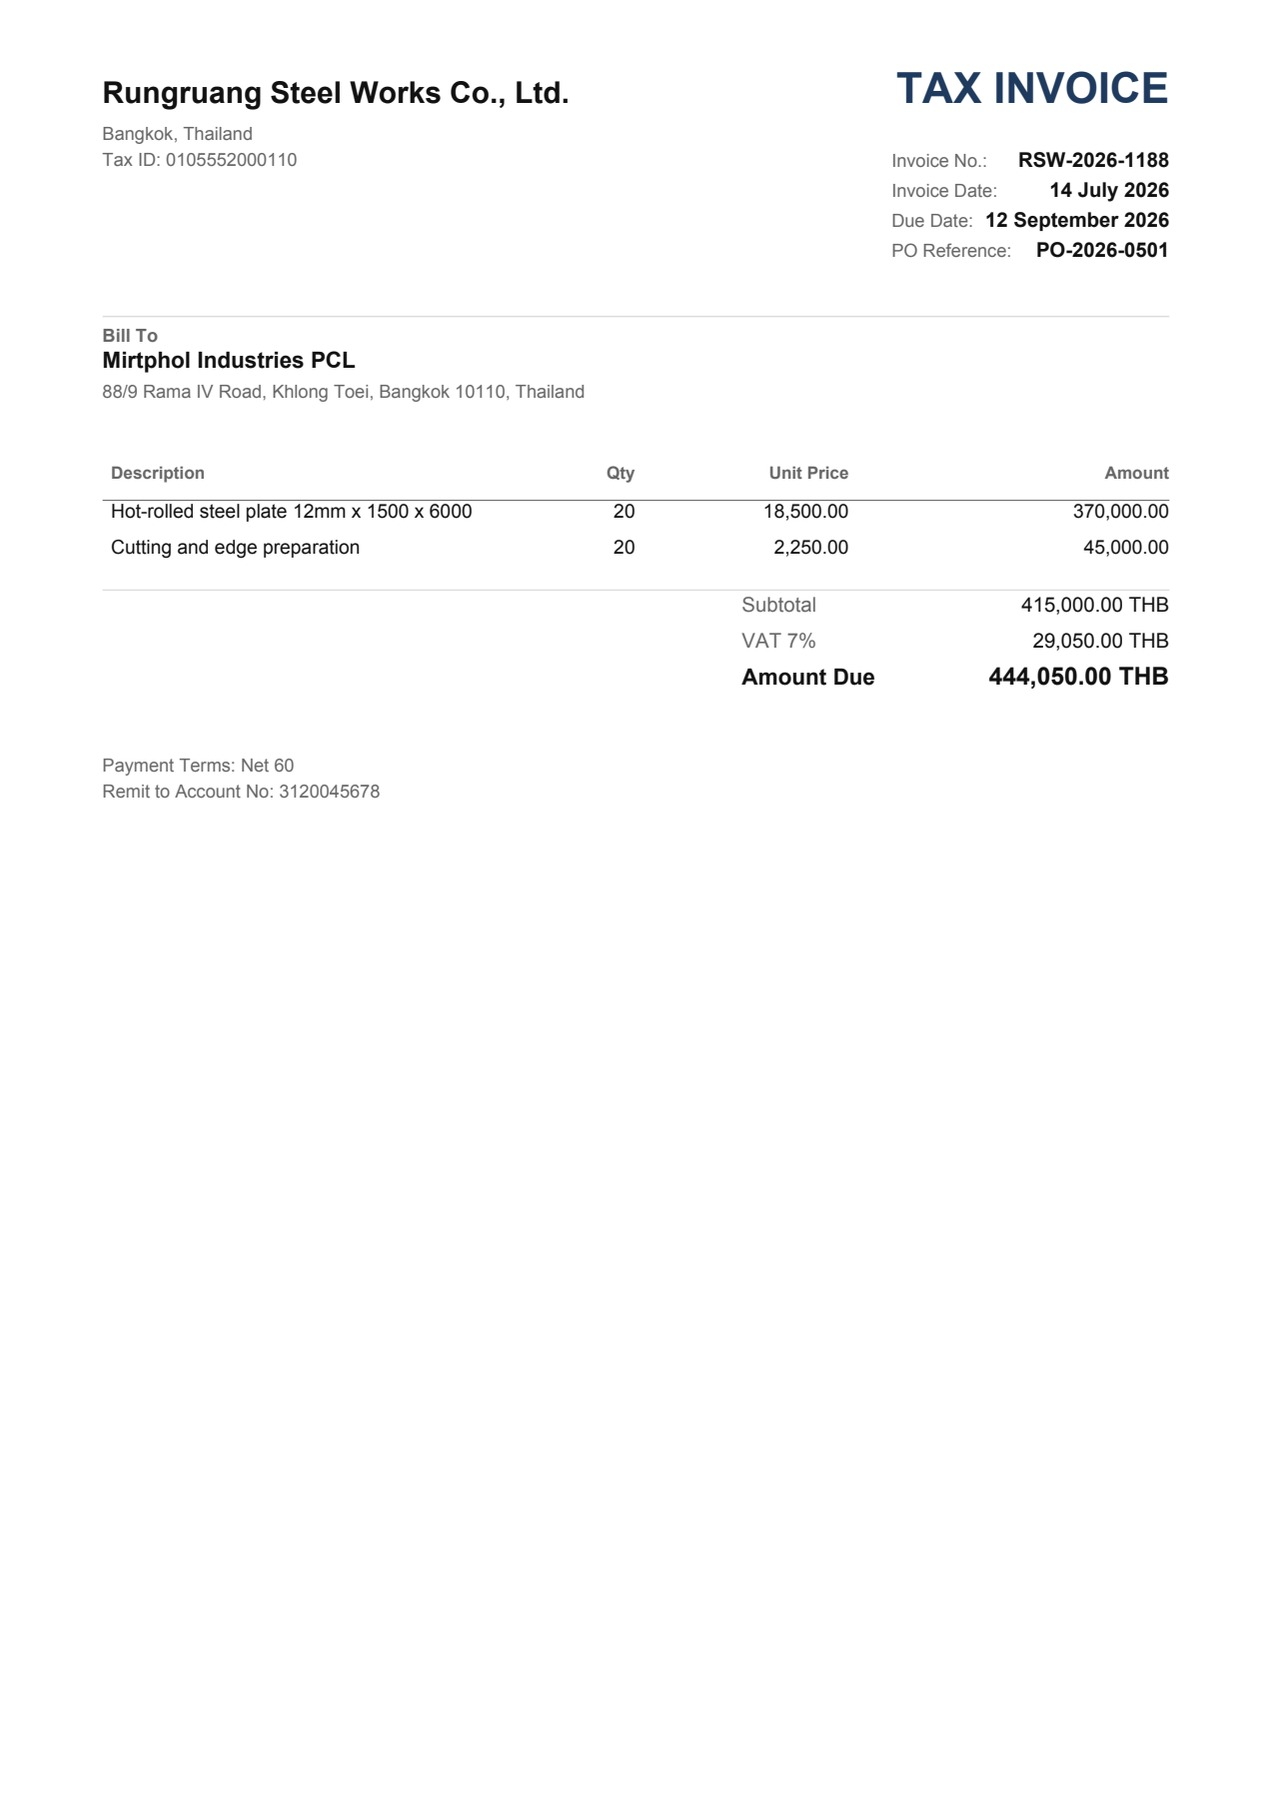

In [11]:
from docuflow.ocr.render import render_document, embedded_text_ratio

stage("render", takes=f"{document_path.suffix.upper()} file, {document_path.stat().st_size:,} bytes",
      gives="one image per page")

pages = render_document(document_path, settings.page_dir / "explained",
                        max_pages=settings.ocr_max_pages, target_dim=settings.ocr_image_dim)

for page in pages:
    print(f"  page {page.page_number}   {page.width} x {page.height} px   {page.path.name}")
print(f"\n  embedded text layer: {embedded_text_ratio(pages):.0%} of pages")
print("  " + ("this PDF carries its own characters — a free, exact reading"
              if embedded_text_ratio(pages) > 0.5
              else "nothing to read but pixels — everything after this is recognition"))

try:
    from IPython.display import Image, display
    display(Image(filename=str(pages[0].path), width=520))
except ImportError:
    print("  page image at", pages[0].path)

### Stage 2 — Clean the page

Four measurements, four possible corrections, and **every correction is thrown
away if the measurement it exists to improve did not improve.**

| Measured | Corrected by | Kept only if |
|---|---|---|
| lighting drift across the page | flattening the illumination | the drift actually fell |
| skew, in degrees | rotating | the page got straighter |
| contrast between ink and paper | stretching | contrast rose |
| sharpness | unsharp mask | sharpness rose |

That gate is the whole design. Preprocessing can only help, because anything that
did not help is reverted and the original goes forward. A clean digital PDF
passes through untouched and writes no second file.

**The order is load-bearing.** Lighting is flattened *before* skew is estimated.
Skew is measured from an ink mask thresholded against the page's mean brightness,
so on a page lit from one side the mask marks the shadow and the measured angle
describes the lighting gradient rather than the text. Getting this backwards left
photographs crooked *and* reverted the deskew as "no better" — it was measuring
the wrong thing twice.

**One output travels further than the rest.** `rescued_pages` are pages that
*arrived* below the legibility floor. Not "was corrected" — arrived broken. The
OCR engine's own quality score cannot see this, because it scores the text that
came back, and text that comes back confidently wrong scores just as well as text
that comes back right. So the page has to be judged before anyone reads it.

In [12]:
from docuflow.ocr.preprocess import prepare_pages

stage("clean", takes=f"{len(pages)} raw page image(s)", gives="pages as the OCR engine will see them")

prepared, report = prepare_pages(pages, enabled=settings.ocr_preprocess)
print(f"  {report.summary}\n")

for page in report.pages:
    b, a = page.before, page.after
    print(f"  page {page.page_number}          before      after     threshold")
    print(f"     skew        {b.skew_degrees:+8.2f}°  {a.skew_degrees:+8.2f}°   fix above 0.40°")
    print(f"     sharpness   {b.sharpness:8.5f}   {a.sharpness:8.5f}   floor 0.00120")
    print(f"     contrast    {b.contrast:8.3f}   {a.contrast:8.3f}   floor 0.180")
    print(f"     lighting    {b.illumination_spread:8.3f}   {a.illumination_spread:8.3f}   ceiling 0.180")
    print(f"     applied  :  {', '.join(page.actions) or 'nothing — the page was already fine'}")
    if page.reverted:
        print(f"     reverted :  {', '.join(page.reverted)}  ← measured no better, so undone")
    for note in page.notes:
        print(f"     note     :  {note}")

if report.rescued_pages:
    print(f"\n  {len(report.rescued_pages)} page(s) arrived below the legibility floor.")
    print("  Every value read from them is marked degraded and cannot post on its own.")
else:
    print("\n  no page arrived illegible")

pages = prepared        # from here on, OCR reads the cleaned pages


  STAGE 2 of 9  ·  CLEAN
  render  [CLEAN]  OCR  classify  read  merge  rules  route  post
  IN   1 raw page image(s)
  OUT  pages as the OCR engine will see them
------------------------------------------------------------------------------


  1 page(s) already clean

  page 1          before      after     threshold
     skew           +0.00°     +0.00°   fix above 0.40°
     sharpness    0.01003    0.01003   floor 0.00120
     contrast       0.331      0.331   floor 0.180
     lighting       0.000      0.000   ceiling 0.180
     applied  :  nothing — the page was already fine

  no page arrived illegible


A clean PDF gives this stage nothing to do, which is the correct outcome but a
dull demonstration. So here is the same stage on a photograph of an invoice
lying on a desk — the case it was built for.

3_invoice_photo_on_a_desk_False.jpg

  skew         -2.80°  ->  +0.00°
  contrast     0.257   ->  0.318
  lighting     0.390   ->  0.008
  applied    evened out the lighting, deskewed -2.7°
  reverted   nothing

as it arrived:


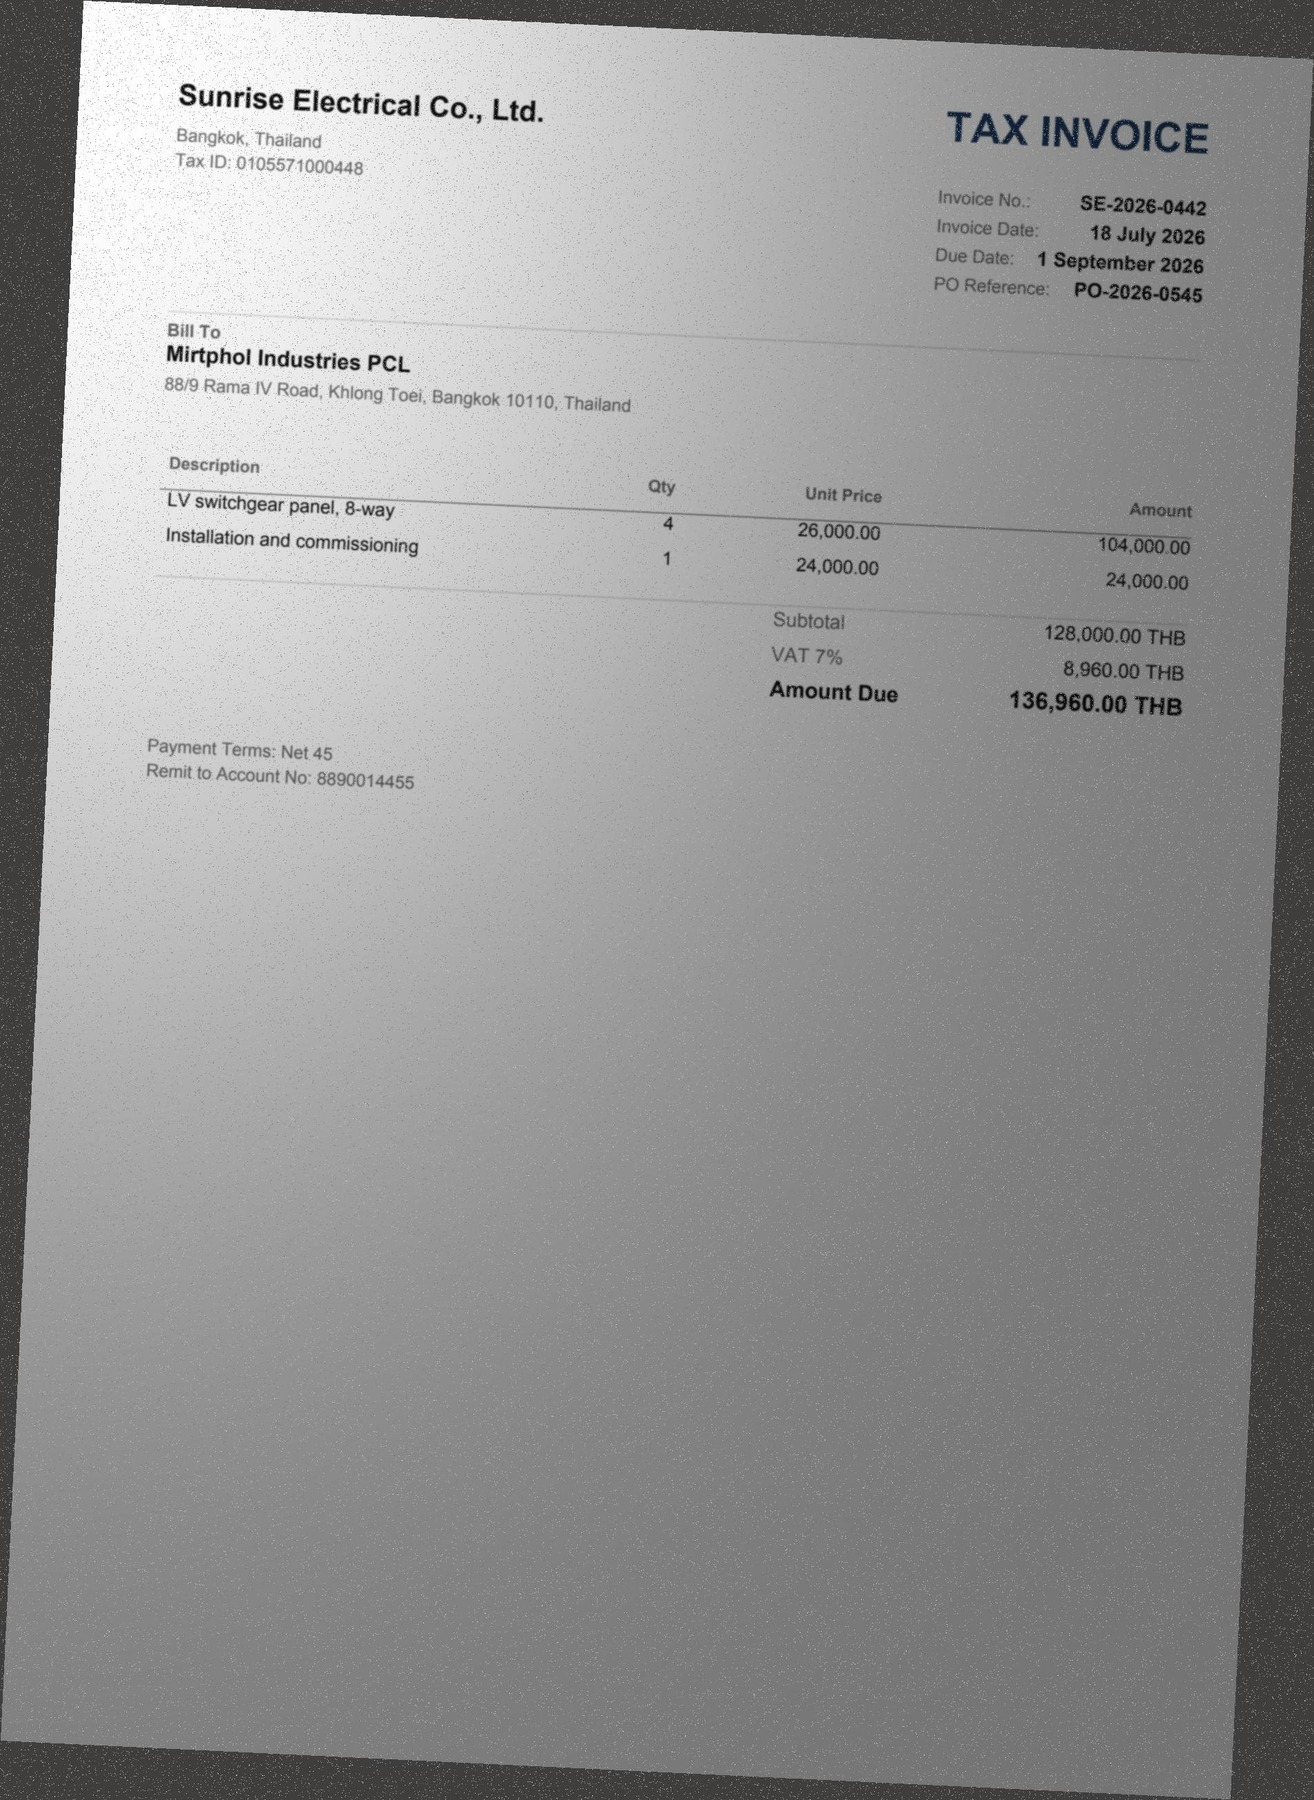

as the model will read it:


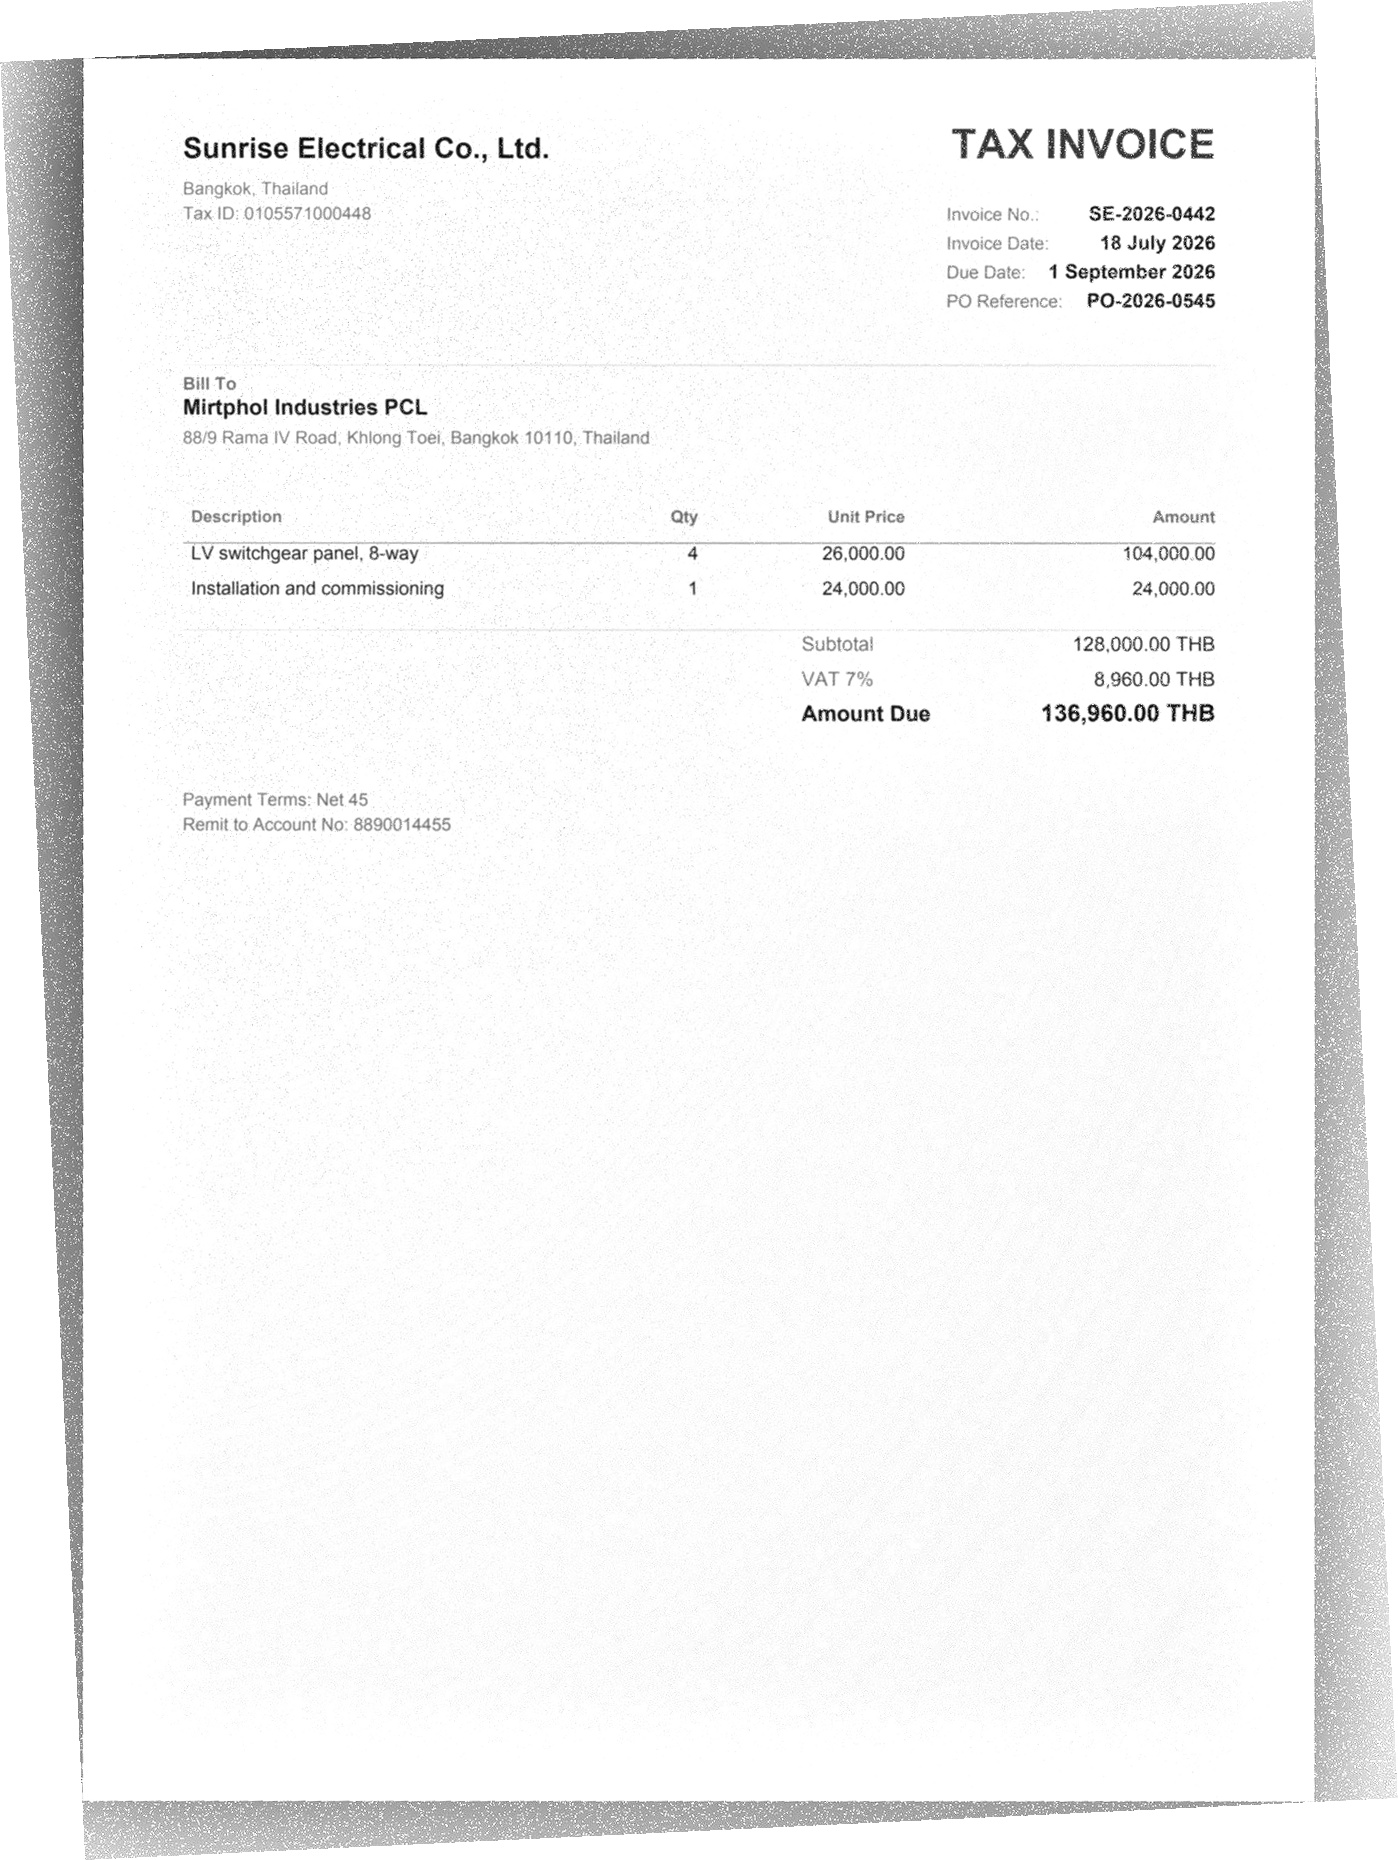

In [13]:
# The same function, on a page that needs it. Nothing else in the notebook uses
# the result; this is here to show the stage doing its job.
photo = next(CORPUS.glob("3_invoice_photo_on_a_desk_*"))
photo_pages = render_document(photo, settings.page_dir / "explained-photo",
                              max_pages=1, target_dim=settings.ocr_image_dim)
photo_prepared, photo_report = prepare_pages(photo_pages, enabled=True)

detail = photo_report.pages[0]
print(f"{photo.name}\n")
print(f"  skew       {detail.before.skew_degrees:+7.2f}°  ->{detail.after.skew_degrees:+7.2f}°")
print(f"  contrast   {detail.before.contrast:7.3f}   ->{detail.after.contrast:7.3f}")
print(f"  lighting   {detail.before.illumination_spread:7.3f}   ->{detail.after.illumination_spread:7.3f}")
print(f"  applied    {', '.join(detail.actions) or 'nothing'}")
print(f"  reverted   {', '.join(detail.reverted) or 'nothing'}")

try:
    from IPython.display import Image, display
    print("\nas it arrived:")
    display(Image(filename=str(photo_pages[0].path), width=360))
    print("as the model will read it:")
    display(Image(filename=str(photo_prepared[0].path), width=360))
except ImportError:
    pass

### Stage 3 — OCR

Page image in, text out. Typhoon OCR 1.5, which is built for Thai documents and
returns **structure as well as characters** — tables come back as HTML, because a
total that stays inside its cell is a total that can still be found later.

Two numbers come out of this stage and they are not the same thing:

* **quality score** — computed on the text that came back. It catches gibberish
  and empty pages.
* **degraded** — set when the page arrived illegible, or when a fallback engine
  had to stand in for the real one.

A page can score well on the first and still be wrong. That is why the second one
exists and why it is carried all the way to the routing decision.

In [14]:
from docuflow.ocr.engine import run_ocr
from docuflow.ocr.quality import score_document_text

stage("OCR", takes=f"{len(pages)} cleaned page image(s)", gives="the text on the page")

ocr = run_ocr(pages, settings)
quality = score_document_text([p.text for p in ocr.pages])

print(f"  engine     {ocr.provider}")
print(f"  took       {ocr.duration_ms / 1000:.1f}s for {len(ocr.pages)} page(s)")
print(f"  produced   {ocr.char_count:,} characters")
print(f"  quality    {quality.score:.2f}   acceptable={quality.acceptable}   degraded={ocr.degraded}")
for reason in quality.reasons:
    print(f"             {reason}")
print()
box(ocr.full_text, limit=1500, label="what the engine returned")


  STAGE 3 of 9  ·  OCR
  render  clean  [OCR]  classify  read  merge  rules  route  post
  IN   1 cleaned page image(s)
  OUT  the text on the page
------------------------------------------------------------------------------


  engine     typhoon-ocr1.5-cloud
  took       2.2s for 1 page(s)
  produced   704 characters
  quality    0.95   acceptable=True   degraded=False

┌─ what the engine returned ──────────────────────────────────────────────────
│ <!-- page 1 -->
│ Rungruang Steel Works Co., Ltd.
│ Bangkok, Thailand
│ Tax ID: 0105552000110
│ 
│ TAX INVOICE
│ 
│ Invoice No.: RSW-2026-1188
│ Invoice Date: 14 July 2026
│ Due Date: 12 September 2026
│ PO Reference: PO-2026-0501
│ 
│ Bill To
│ Mirphol Industries PCL
│ 88/9 Rama IV Road, Khlong Toei, Bangkok 10110, Thailand
│ 
│ <table><tr><td>Description</td><td>Qty</td><td>Unit Price</td><td>Amount</td
│ 
│ Subtotal 415,000.00 THB
│ VAT 7% 29,050.00 THB
│ Amount Due **444,050.00 THB**
│ 
│ Payment Terms: Net 60
│ Remit to Account No: 3120045678
└─────────────────────────────────────────────────────────────────────────────


### Stage 4 — Classify

Which kind of document is this? The answer chooses the **schema** — the list of
fields to look for and which of them are critical — so everything after this
depends on getting it right.

Keywords first, and a model only if the keywords are close. That ordering is
worth stating plainly: an invoice that says "INVOICE" at the top does not need a
model call to prove it, and the cheapest correct answer is the best one.

In [15]:
from docuflow.agents.classifier import classify, classify_by_keywords
from docuflow.schemas.registry import get_schema

stage("classify", takes=f"{ocr.char_count:,} characters", gives="a document type and its schema")

doc_type, keyword_confidence, scores = classify_by_keywords(ocr.full_text)
print("  keyword scores")
for name, score in sorted(scores.items(), key=lambda kv: -kv[1])[:5]:
    print(f"     {name:16} {score:5.2f}" + ("   <- best" if name == doc_type else ""))

result = classify(ocr.full_text, primary)
schema = get_schema(result.doc_type)

print(f"\n  decided    {result.doc_type}   ({result.confidence:.0%})")
print(f"  method     {result.method}"
      + ("   ← keywords were decisive; no model was called" if result.method == "keywords" else ""))
print(f"\n  schema     {len(schema.fields)} fields, "
      f"{len(schema.required_fields)} required, {len(schema.critical_fields)} critical")
print(f"  critical   {', '.join(sorted(s.name for s in schema.critical_fields))}")
print("             ^ a wrong value in one of these is a wrong payment")
print(f"\n  all fields {', '.join(spec.name for spec in schema.fields)}")


  STAGE 4 of 9  ·  CLASSIFY
  render  clean  OCR  [CLASSIFY]  read  merge  rules  route  post
  IN   704 characters
  OUT  a document type and its schema
------------------------------------------------------------------------------
  keyword scores
     invoice           7.00   <- best
     form              1.05
     receipt           0.70
     contract          0.35
     purchase_order    0.00

  decided    invoice   (95%)
  method     keywords   ← keywords were decisive; no model was called

  schema     14 fields, 4 required, 7 critical
  critical   bank_account, invoice_number, purchase_order_ref, subtotal, tax_amount, total_amount, vendor_name
             ^ a wrong value in one of these is a wrong payment

  all fields invoice_number, invoice_date, due_date, vendor_name, vendor_tax_id, buyer_name, purchase_order_ref, currency, subtotal, tax_rate, tax_amount, total_amount, payment_terms, bank_account


### Stage 5 — Read it twice, with two different models

Both channels get the same OCR text and the same schema. Nothing else is shared:
different backends, different prompts, neither one sees the other's answer.

* **Channel A — Typhoon, field-first.** Walks the schema: "find the total, find
  the invoice number, find the tax ID."
* **Channel B — Claude, label-first.** Walks the page: "here are the labels I can
  see and what sits next to each one."

Approaching the same page from opposite directions is deliberate. Two prompts
that think alike fail alike.

Notice the **evidence** column. Every value comes back with the span of text the
model claims to have read it from, and that quote is checked against the page in
the next stage. A model that produces a plausible total and cannot point at it
has invented it.

In [16]:
import time
from docuflow.agents.llm_extractor import extract_with_llm

stage("read", takes=f"{ocr.char_count:,} characters + a {len(schema.fields)}-field schema",
      gives="channel A's answer, with a quote for each value")

started = time.perf_counter()
primary_read = extract_with_llm(ocr.full_text, schema, primary)
print(f"  {getattr(primary, 'model', primary)} — {time.perf_counter() - started:.1f}s, "
      f"ok={primary_read.ok} {primary_read.note}\n")

print(f"  {'FIELD':22} {'VALUE':28} QUOTED FROM THE PAGE")
for name, candidate in sorted(primary_read.candidates.items()):
    print(f"  {name:22} {str(candidate.raw_value)[:27]:28} {(candidate.evidence or '')[:40]!r}")


  STAGE 5 of 9  ·  READ
  render  clean  OCR  classify  [READ]  merge  rules  route  post
  IN   704 characters + a 14-field schema
  OUT  channel A's answer, with a quote for each value
------------------------------------------------------------------------------


  typhoon-v2.5-30b-a3b-instruct — 3.3s, ok=True 

  FIELD                  VALUE                        QUOTED FROM THE PAGE
  bank_account           3120045678                   'Remit to Account No: 3120045678'
  buyer_name             Mirphol Industries PCL       'Bill To\nMirphol Industries PCL'
  currency               THB                          'Subtotal 415,000.00 THB'
  due_date               2026-09-12                   'Due Date: 12 September 2026'
  invoice_date           2026-07-14                   'Invoice Date: 14 July 2026'
  invoice_number         RSW-2026-1188                'Invoice No.: RSW-2026-1188'
  payment_terms          Net 60                       'Payment Terms: Net 60'
  purchase_order_ref     PO-2026-0501                 'PO Reference: PO-2026-0501'
  subtotal               415000.00                    'Subtotal 415,000.00 THB'
  tax_amount             29050.00                     'VAT 7% 29,050.00 THB'
  tax_rate               7%                        

In [17]:
from docuflow.agents.verify_extractor import verify_with_llm
from docuflow.agents.rule_extractor import extract_with_rules

started = time.perf_counter()
secondary_read = verify_with_llm(ocr.full_text, schema, verify)
elapsed = time.perf_counter() - started

if secondary_read.ok:
    print(f"  channel B: {getattr(verify, 'model', None) or 'model'} — {elapsed:.1f}s\n")
    print(f"  {'FIELD':22} {'VALUE':28} QUOTED FROM THE PAGE")
    for name, candidate in sorted(secondary_read.candidates.items()):
        print(f"  {name:22} {str(candidate.raw_value)[:27]:28} {(candidate.evidence or '')[:40]!r}")
else:
    print(f"  no second model ({secondary_read.note})")
    print("  falling back to the deterministic label matcher — the agreement")
    print("  column in the next stage will be much less informative.\n")
    for name, candidate in sorted(extract_with_rules(
            [(p.page_number, p.text) for p in ocr.pages], schema).items()):
        print(f"  {name:22} {str(candidate.raw_value)[:27]:28}")

  channel B: claude-sonnet-5 — 5.3s

  FIELD                  VALUE                        QUOTED FROM THE PAGE
  bank_account           3120045678                   'Remit to Account No: 3120045678'
  buyer_name             Mirphol Industries PCL       'Bill To\nMirphol Industries PCL'
  currency               THB                          'Subtotal 415,000.00 THB'
  due_date               12 September 2026            'Due Date: 12 September 2026'
  invoice_date           14 July 2026                 'Invoice Date: 14 July 2026'
  invoice_number         RSW-2026-1188                'Invoice No.: RSW-2026-1188'
  payment_terms          Net 60                       'Payment Terms: Net 60'
  purchase_order_ref     PO-2026-0501                 'PO Reference: PO-2026-0501'
  subtotal               415,000.00                   'Subtotal 415,000.00 THB'
  tax_amount             29,050.00                    'VAT 7% 29,050.00 THB'
  tax_rate               7%                           'VAT 7% 29

### Stage 6 — Merge, ground, score

Three things happen here and it is worth keeping them apart, because they fail
for different reasons.

**Merge.** Do the two channels agree? Compared *after normalising*, so
`8 July 2026` and `2026-07-08` are the same day and `187,000.00 THB` is the same
number as `187000.0`. Comparing the raw strings would report disagreements the
system correctly did not have.

**Ground.** Is the quoted evidence really on the page? Checked against the OCR
text, not taken on trust.

**Score.** Confidence per field, and it answers exactly one question: *did we read
this correctly.* Not "is this document acceptable" — that is the routing stage's
job, and keeping the two apart matters more than it sounds. When they were one
number, three advisory findings took a perfectly-read document from 95% to 72%
under an 84% threshold, and fifteen of eighteen documents ended up held by
warnings that were never meant to hold anything.

**What grounding cannot do.** It proves a value came from text on the page. If
the OCR misread the page, the wrong value *is* on the page as far as grounding
can tell — and so is the quote. Two channels reading the same OCR text cannot
catch it either. The defences against a misread are the arithmetic rules in the
next stage and the legibility signal from stage 2.

In [18]:
from docuflow.agents.candidates import from_llm, from_rule
from docuflow.agents.merge import merge_all

stage("merge", takes="two independent readings", gives="one field list, grounded and scored")

pairs = [(p.page_number, p.text) for p in ocr.pages]
channel_a = {n: from_llm(n, c.raw_value, c.evidence, channel="model")
             for n, c in primary_read.candidates.items()}
if secondary_read.ok:
    channel_b = {n: from_llm(n, c.raw_value, c.evidence, channel="verify")
                 for n, c in secondary_read.candidates.items()}
else:
    channel_b = {n: from_rule(c) for n, c in extract_with_rules(pairs, schema).items()}

fields = merge_all(schema, channel_a, channel_b, pairs, quality.score, ocr.degraded)

def agreement(field):
    if any("the two readings disagree" in note for note in field.notes):
        return "DISAGREED"
    return "both agreed" if field.name in channel_a and field.name in channel_b else "one channel only"

critical = {s.name for s in schema.critical_fields}
print(f"  {'FIELD':20} {'VALUE':26} {'CONF':>5} {'ON PAGE':>8}  CHANNELS")
for field in fields:
    if field.is_empty:
        continue
    mark = "*" if field.name in critical else " "
    print(f" {mark}{field.name:20} {str(field.value)[:25]:26} {field.confidence:>4.0%} "
          f"{('yes' if field.grounded else 'NO'):>8}  {agreement(field)}")

print("\n  * = critical field: a wrong value here is a wrong payment")
empty = [f.name for f in fields if f.is_empty]
if empty:
    print("  not found on the page:", ", ".join(empty))


  STAGE 6 of 9  ·  MERGE
  render  clean  OCR  classify  read  [MERGE]  rules  route  post
  IN   two independent readings
  OUT  one field list, grounded and scored
------------------------------------------------------------------------------
  FIELD                VALUE                       CONF  ON PAGE  CHANNELS
 *invoice_number       RSW-2026-1188               95%      yes  both agreed
  invoice_date         2026-07-14                  95%      yes  both agreed
  due_date             2026-09-12                  95%      yes  both agreed
 *vendor_name          Rungruang Steel Works Co.   95%      yes  both agreed
  vendor_tax_id        0105552000110               95%      yes  both agreed
  buyer_name           Mirphol Industries PCL      95%      yes  both agreed
 *purchase_order_ref   PO-2026-0501                95%      yes  both agreed
  currency             THB                         95%      yes  both agreed
 *subtotal             415000.0                    95%      yes

In [19]:
# Why "both agreed" when the two channels plainly typed different strings.
#
# Agreement is decided *after* normalising. "415,000.00 THB" and "415000.00" are
# the same number; "14 July 2026" and "2026-07-14" are the same day. Comparing
# the raw strings would report a disagreement on almost every field and make the
# agreement signal worthless — which is the signal the whole second call exists
# to produce.
print(f"  {'FIELD':20} {'CHANNEL A TYPED':26} {'CHANNEL B TYPED':26} STORED AS")
differences = 0
for field in fields:
    left, right = channel_a.get(field.name), channel_b.get(field.name)
    if left is None or right is None or str(left.raw_value) == str(right.raw_value):
        continue
    differences += 1
    print(f"  {field.name:20} {str(left.raw_value)[:25]:26} {str(right.raw_value)[:25]:26} {field.value!r}")

print(f"\n  {differences} field(s) were written differently by the two models")
print("  and still counted as agreement, because after normalising they are equal.")

  FIELD                CHANNEL A TYPED            CHANNEL B TYPED            STORED AS
  invoice_date         2026-07-14                 14 July 2026               '2026-07-14'
  due_date             2026-09-12                 12 September 2026          '2026-09-12'
  subtotal             415000.00                  415,000.00                 415000.0
  tax_amount           29050.00                   29,050.00                  29050.0
  total_amount         444050.00                  444,050.00 THB             444050.0

  5 field(s) were written differently by the two models
  and still counted as agreement, because after normalising they are equal.


In [20]:
# Anything the page did not support. This is the list a reviewer actually needs:
# not "the model was 91% sure", but "here is the line it says it read, and that
# line is not on the page".
ungrounded = [f for f in fields if not f.is_empty and not f.grounded]
if not ungrounded:
    print("every populated field is traceable to a span of text on the page")
for field in ungrounded:
    print(f"{field.name:20} = {field.value!r}")
    print(f"{'':20}   claimed to have read: {(field.evidence or '')[:60]!r}")
    print(f"{'':20}   notes: {', '.join(field.notes) or '-'}")

every populated field is traceable to a span of text on the page


In [21]:
# The line-item table, read deterministically — no model. It is a table; the
# structure is the answer, and a model is not needed to see rows.
from docuflow.agents.rule_extractor import find_line_items
from docuflow.models import LineItem
from docuflow.normalize.amounts import parse_money, parse_number

rows = find_line_items(pairs) if schema.has_line_items else []
line_items = tuple(
    LineItem(description=str(r.get("description", ""))[:300],
             quantity=parse_number(r.get("quantity")),
             unit_price=parse_money(r.get("unit_price")),
             amount=parse_money(r.get("amount")), confidence=0.8)
    for r in rows
)

print(f"{len(line_items)} line item(s) read\n")
for item in line_items:
    print(f"  {item.description[:38]:40} {item.quantity or 0:>6}  x {item.unit_price or 0:>12,.2f}"
          f"  = {item.amount or 0:>13,.2f}")
if line_items:
    print(f"  {'':40} {'':6}    {'':12}    {'-' * 13}")
    print(f"  {'sum of the lines':40} {'':6}    {'':12}   {sum(i.amount or 0 for i in line_items):>13,.2f}")

2 line item(s) read

  Hot-rolled steel plate 12mm x 1500 x 6     20.0  x    18,500.00  =    370,000.00
  Cutting and edge preparation               20.0  x     2,250.00  =     45,000.00
                                                                     -------------
  sum of the lines                                                     415,000.00


### Stage 7 — Rules

Now the document is checked. Twenty-six built-in checks of three kinds:

1. **Does it agree with itself?** Lines sum to the subtotal, subtotal × rate is
   the tax, subtotal + tax is the total. Recomputed, not trusted.
2. **Does it agree with our records?** Vendor in the master file, purchase order
   exists and covers it, contract still valid, not already posted.
3. **Is it sane?** Dates not absurd, VAT at a rate that exists, tax ID checksum.

**Two tolerances, never merged.** `AMOUNT_TOLERANCE` (2%) is how far an invoice
may differ from the *purchase order* it quotes — a commercial allowance.
`ARITHMETIC_TOLERANCE` (0.01%) is how far a document may differ from *itself* —
rounding, and nothing else. Sharing one number let an 810-baht misread post as
"the totals add up" on a 200,090-baht invoice.

**Three severities, and they must behave differently:**

| | what it does |
|---|---|
| `blocking` | stops the document. Nothing posts past one, even on approval. |
| `warning` | recorded, shown to a reviewer, and **holds nothing**. |
| `info` | a note. |

A warning that holds documents is a blocking rule that has not admitted it, and
it is how a human-in-the-loop system ends up with a human in every loop.

> **Why the count below is under twenty-six.** A rule reports only when it has
> something to say. `contract_dates_ordered` on an invoice is not a pass — there
> are no contract dates — so it returns nothing rather than a green tick it did
> not earn. The evaluation treats this the same way: a rule that no document
> exercised is *untested*, not passing.

In [22]:
from datetime import date
from docuflow.rules import RuleContext, run_rules
from docuflow.store.records import RecordStore, reference_field_for

stage("rules", takes=f"{len([f for f in fields if not f.is_empty])} fields + the master registers",
      gives="a finding per check")

records = RecordStore(settings.db_path)
by_name = {f.name: f for f in fields}

def value(name):
    field = by_name.get(name)
    return None if field is None or field.is_empty else field.value

vendor_name = value("vendor_name") or value("merchant_name") or value("applicant_name")
tax_id = value("vendor_tax_id") or value("merchant_tax_id") or value("tax_id")
vendor_match = master.find_vendor(str(vendor_name) if vendor_name else None,
                                  str(tax_id) if tax_id else None)
reference = value(reference_field_for(result.doc_type))

context = RuleContext(
    document_id="EXPLAINED-1",
    doc_type=result.doc_type,
    schema=schema,
    fields=fields,
    line_items=line_items,
    master=master,
    vendor_match=vendor_match,
    ocr_text=ocr.full_text,
    ocr_degraded=ocr.degraded,
    today=date.today(),
    duplicate_of=records.find_duplicate(result.doc_type, str(reference) if reference else None,
                                        vendor_match.vendor_id),
    **RuleContext.policy_from(settings),
)

findings = run_rules(context)
failed = [f for f in findings if not f.passed]

print(f"  vendor lookup : {vendor_match.method}"
      + (f" -> {vendor_match.vendor['legal_name']}" if vendor_match.vendor else " -> no match"))
print(f"  checks run    : {len(findings)}")
print(f"  passed        : {len(findings) - len(failed)}")
print(f"  failed        : {len(failed)}\n")

for severity in ("blocking", "warning", "info"):
    hits = [f for f in failed if f.severity == severity]
    if not hits:
        continue
    effect = {"blocking": "stops the document",
              "warning": "shown, but holds nothing",
              "info": "a note"}[severity]
    print(f"  {severity.upper()}  ({effect})")
    for finding in hits:
        print(f"     {finding.rule_id}")
        print(f"        {finding.message}")

if not failed:
    print("  everything passed")
    print("\n  What was actually checked:")
    for finding in findings[:10]:
        print(f"     ok  {finding.rule_id}")
    if len(findings) > 10:
        print(f"     ... and {len(findings) - 10} more")


  STAGE 7 of 9  ·  RULES
  render  clean  OCR  classify  read  merge  [RULES]  route  post
  IN   14 fields + the master registers
  OUT  a finding per check
------------------------------------------------------------------------------
  vendor lookup : tax id -> Rungruang Steel Works Co., Ltd.
  checks run    : 16
  passed        : 16
  failed        : 0

  everything passed

  What was actually checked:
     ok  tax_id_checksum
     ok  dates_not_in_future
     ok  invoice_totals_consistent
     ok  tax_rate_consistent
     ok  vat_rate_expected
     ok  line_items_sum_to_subtotal
     ok  vendor_known
     ok  vendor_active
     ok  bank_account_matches_vendor
     ok  purchase_order_required
     ... and 6 more


#### When something is wrong, which value is wrong?

"The totals do not add up" tells a reviewer to go and find the mistake. Naming
the field saves them the search.

The trick is knowing when to keep quiet. Three relations connect four numbers —
`lines → subtotal`, `subtotal × rate → tax`, `subtotal + tax → total`. When a
document breaks one of them, sometimes exactly one field explains every broken
relation while leaving the intact ones intact; that field is nameable. Often two
different fields would explain it equally well, and then **the honest answer is
silence**. A wrong number wearing a suggestion's confidence is worse than no
suggestion.

The cell below runs the diagnosis on four bare numbers — no document, no model —
so both answers are visible.

In [23]:
from docuflow.rules.repair import Money, blame, best_of

# What the diagnosis said about this document, if anything.
fixes = best_of(fix for finding in failed for fix in finding.fixes)
if fixes:
    for fix in fixes:
        print(f"[{'suggested fix' if fix.confidence >= 0.85 else 'worth checking'}]  {fix.field}")
        print(f"     read as   {fix.current!r}")
        print(f"     should be {fix.suggested!r}   ({fix.confidence:.0%}, from {fix.source})")
        print(f"     because   {fix.reason}\n")
else:
    print("nothing on this document could be diagnosed from its own arithmetic.\n")

# The two answers, side by side, on numbers alone.
print("-" * 78)
print("corpus document 2 — the lines and the VAT both say 44,940; the total reads 49,440")
settled = Money(subtotal=42_000.0, tax_amount=2_940.0, tax_rate=7.0,
                total_amount=49_440.0, line_total=42_000.0)
found = blame(settled)
print(f"   -> {found.field} reads {found.current:,.2f}, should be {found.suggested:,.2f}")
print(f"      two other relations still hold, and they are what rule out the alternatives:")
print(f"      {', '.join(found.corroborated_by)}")

print("\nthe same disagreement with nothing else to check it against")
ambiguous = Money(subtotal=42_000.0, tax_amount=2_940.0, total_amount=49_440.0)
print(f"   -> {blame(ambiguous)}   ← and that is the right answer")
print("      Either the subtotal or the total could be the misread one.")
print("      Nothing here can choose, so nothing is offered.")

nothing on this document could be diagnosed from its own arithmetic.

------------------------------------------------------------------------------
corpus document 2 — the lines and the VAT both say 44,940; the total reads 49,440
   -> total_amount reads 49,440.00, should be 44,940.00
      two other relations still hold, and they are what rule out the alternatives:
      rate, lines

the same disagreement with nothing else to check it against
   -> None   ← and that is the right answer
      Either the subtotal or the total could be the misread one.
      Nothing here can choose, so nothing is offered.


### Stage 8 — Route

Two numbers meet here and they are not the same thing.

**Confidence** is about *reading*: how sure are we that these values are what is
printed on the page. Only failures in `MISREAD_SIGNALS` move it — checks whose
failure implies something was read wrong — weighted by severity (blocking 0.20,
warning 0.05). An unknown vendor does not lower it: that is a real problem, and
it is not a reading problem.

**The decision** is about *policy*: may this post. Made in `routing.decide`, in
code, from the findings and the confidence together.

Keeping them apart is what lets a warning be a warning.

In [24]:
from docuflow.confidence import document_confidence
from docuflow.routing import decide
from docuflow.models import DocumentRun, SourceInfo

stage("route", takes=f"{len(findings)} findings + per-field confidence", gives="post, or hold for a person")

run = DocumentRun(
    document_id="EXPLAINED-1",
    source=SourceInfo(filename=document_path.name, sha256="0" * 64, byte_size=1),
    doc_type=result.doc_type,
    ocr=ocr,
    fields=fields,
    findings=findings,
)
run = run.evolve(confidence=document_confidence(
    fields, findings,
    frozenset(s.name for s in schema.required_fields),
    frozenset(s.name for s in schema.critical_fields)))

outcome = decide(run, schema, settings.auto_post_min_confidence)

print(f"  confidence   {run.confidence:>6.0%}   (threshold {settings.auto_post_min_confidence:.0%})")
print(f"  decision     {outcome.decision.upper()}")
print(f"  expected     {'posts' if expected_to_post else 'held'}  (from the filename)")
print(f"  agreement    {'correct' if (outcome.decision == 'auto_post') == expected_to_post else 'WRONG — worth investigating'}\n")
for reason in outcome.reasons:
    print("   •", reason)
if not outcome.reasons:
    print("   • nothing stood in the way")


  STAGE 8 of 9  ·  ROUTE
  render  clean  OCR  classify  read  merge  rules  [ROUTE]  post
  IN   16 findings + per-field confidence
  OUT  post, or hold for a person
------------------------------------------------------------------------------
  confidence      95%   (threshold 84%)
  decision     AUTO_POST
  expected     posts  (from the filename)
  agreement    correct

   • Confidence 95% with no blocking issues; every required field was found, and 7 critical value(s) trace to text on the page.


### Stage 9 — Post

Everything above, in one call, on the same document. `Pipeline.process_file` runs
the identical functions in the identical order — the stages you just stepped
through are not a demonstration path, they are the path.

The trace at the bottom shows where the time actually went, which is the only
honest basis for deciding what to optimise.

In [25]:
from docuflow.pipeline import Pipeline

stage("post", takes="the file, again, from the top", gives="a stored record or a review task")

whole = Pipeline(settings).process_file(document_path, source_kind="path")
processed = whole.run

print(f"  document   {processed.document_id}")
print(f"  type       {processed.doc_type}")
print(f"  decision   {processed.decision.upper()}   ({processed.confidence:.0%})")
print(f"  record     {processed.record_id or '— not posted'}\n")

print(f"  {'STAGE':12} {'STATUS':>8} {'TIME':>7}   WHAT IT DID")
for step in processed.trace:
    print(f"  {step.step:12} {step.status:>8} {step.duration_ms / 1000:>6.1f}s   {step.summary[:44]}")

total = sum(s.duration_ms for s in processed.trace) / 1000
print(f"  {'':12} {'':8} {total:>6.1f}s   total")


  STAGE 9 of 9  ·  POST
  render  clean  OCR  classify  read  merge  rules  route  [POST]
  IN   the file, again, from the top
  OUT  a stored record or a review task
------------------------------------------------------------------------------


  document   DOC-38079ECB6C
  type       invoice
  decision   AUTO_POST   (93%)
  record     REC-19B735649A

  STAGE          STATUS    TIME   WHAT IT DID
  render             ok    0.0s   Rendered 1 page(s)
  preprocess         ok    0.2s   1 page(s) already clean
  ocr                ok    1.6s   typhoon-ocr1.5-cloud read 704 characters fro
  classify           ok    0.0s   Invoice / Tax Invoice (95%) via keywords
  extract            ok    8.9s   14/14 fields extracted, 12 confirmed by both
  line_items         ok    0.0s   2 line item(s) read
  validate           ok    0.0s   16/16 checks passed
  route              ok    0.0s   auto post (confidence 93%)
  archive            ok    0.0s   Filed under invoice/2026-08
  post               ok    0.0s   Posted to the ledger as REC-19B735649A
                          10.8s   total


In [26]:
# The record itself — the thing this whole notebook exists to produce.
print(f"{'FIELD':22} {'VALUE':34} {'CONF':>5}  ON PAGE")
for field in processed.fields:
    if field.is_empty:
        continue
    print(f"{field.name:22} {str(field.value)[:33]:34} {field.confidence:>4.0%}  "
          + ("yes" if field.grounded else "NO"))

print("\nrouted that way because:")
for reason in processed.decision_reasons:
    print("  •", reason)

FIELD                  VALUE                               CONF  ON PAGE
invoice_number         RSW-2026-1188                       95%  yes
invoice_date           2026-07-14                          95%  yes
due_date               2026-09-12                          95%  yes
vendor_name            Rungruang Steel Works Co., Ltd.     84%  yes
vendor_tax_id          0105552000110                       95%  yes
buyer_name             Mirphol Industries PCL              95%  yes
purchase_order_ref     PO-2026-0501                        95%  yes
currency               THB                                 84%  yes
subtotal               415000.0                            95%  yes
tax_rate               7.0                                 95%  yes
tax_amount             29050.0                             95%  yes
total_amount           444050.0                            95%  yes
payment_terms          Net 60                              95%  yes
bank_account           3120045678          

## Part 2 — Writing a rule by typing a sentence

The twenty-six built-in checks encode a generic finance policy. Yours is
different, and it changes — usually on a day when nobody has time to open an
editor.

So a rule can be written in plain language. **A model is used exactly once,
here**, to translate the sentence into a condition. It never sees a document and
it is never consulted again: the compiled rule is read back to you in words,
saved as data, and from then on evaluated by an expression engine.

That boundary is the whole design, and it is worth being precise about why:

> Asking a model on every document *"is the VAT right on this one?"* makes the
> answer depend on the document's own wording — which is exactly what a careless
> supplier, or an attacker, controls.
>
> Asking it once, in front of the person who will approve the result, does not.

### What a rule can look at

Every field in the document's schema, plus six facts about the document that are
not fields. Nothing else — a rule cannot invent a name.

In [27]:
from docuflow.rules.custom import DOCUMENT_FACTS, fields_for, values_for

available = sorted(fields_for(result.doc_type))
snapshot = values_for(context)

print(f"a rule about a {result.doc_type} may reference {len(available)} names:\n")
print(f"  {'NAME':24} {'THIS DOCUMENT':30} WHAT IT IS")
for name in available:
    shown = str(snapshot.get(name))[:29] if snapshot.get(name) is not None else "—"
    note = DOCUMENT_FACTS.get(name, "a field on the document")
    print(f"  {name:24} {shown:30} {note[:34]}")

a rule about a invoice may reference 20 names:

  NAME                     THIS DOCUMENT                  WHAT IT IS
  bank_account             3120045678                     a field on the document
  buyer_name               Mirphol Industries PCL         a field on the document
  currency                 THB                            a field on the document
  doc_type                 invoice                        The kind of document (invoice, rec
  due_date                 2026-09-12                     a field on the document
  duplicate_found          False                          true when this document matches so
  invoice_date             2026-07-14                     a field on the document
  invoice_number           RSW-2026-1188                  a field on the document
  line_item_count          2                              How many line items were read from
  ocr_degraded             False                          true when the page was recognised 
  payment_terms    

### Type a sentence, get a rule

Change `PROMPT` and re-run. The cell prints, in order: what you typed, what the
compiler made of it, how it reads back in words, and the JSON it will be stored
as.

Note what `assert` means: **it is what must be true for a document to pass.** A
request phrased as "warn when X" compiles to `assert: not X`. Getting that
backwards produces a rule that fires on every good document and passes every bad
one, so the compiler is explicitly told to invert.

In [28]:
import json as _json
from docuflow.rules.authoring import compile_rule

PROMPT = "invoices over 100,000 baht must quote a purchase order"

draft = compile_rule(PROMPT, ("invoice",), primary, mode="expression")

if not draft.ok:
    print("could not compile:", draft.error)
else:
    rule = draft.rule
    print("you typed")
    print(f"   {PROMPT}\n")
    print("compiled to")
    print(f"   id       {rule.rule_id}")
    print(f"   severity {rule.severity}   ({'stops the document' if rule.severity == 'blocking' else 'flagged, but posts'})")
    print(f"   applies  {', '.join(rule.doc_types)}\n")
    print("reads back as")
    print(f"   {rule.explanation}\n")
    print("a reviewer sees, on failure")
    print(f"   {rule.message}\n")
    print("stored as")
    for line in _json.dumps({"when": rule.when, "assert": rule.assert_}, indent=2).splitlines():
        print("   " + line)

you typed
   invoices over 100,000 baht must quote a purchase order

compiled to
   id       invoice_over_100k_baht_must_have_po
   severity blocking   (stops the document)
   applies  invoice

reads back as
   When total_amount is at least 100000 and currency is 'THB', require that purchase_order_ref is present.

a reviewer sees, on failure
   This invoice exceeds 100,000 THB and does not reference a purchase order.

stored as
   {
     "when": {
       "all": [
         {
           "field": "total_amount",
           "op": "gte",
           "value": 100000
         },
         {
           "field": "currency",
           "op": "eq",
           "value": "THB"
         }
       ]
     },
     "assert": {
       "field": "purchase_order_ref",
       "op": "present"
     }
   }


### And run it, right now, against the document from Part 1

A rule that reads well in a sentence can still be inverted or vacuous. The fix is
to try it on a document you already understand before it is saved anywhere.

In [29]:
from docuflow.rules.custom import run_custom_rule

if draft.ok:
    verdict = run_custom_rule(draft.rule, context)
    if verdict is None:
        print(f"{draft.rule.rule_id}: does not apply to this document")
        print("   (its `when` guard did not match — that is not a pass and not a failure)")
    else:
        print(f"{draft.rule.rule_id}: {'PASSED' if verdict.passed else 'FAILED'}")
        print(f"   {verdict.message}")
        observed = verdict.detail.get("observed") or {}
        if observed:
            print("   it looked at:")
            for name, seen in observed.items():
                print(f"      {name} = {seen!r}")

invoice_over_100k_baht_must_have_po: PASSED
   Invoice over 100,000 THB must quote a purchase order: satisfied.
   it looked at:
      purchase_order_ref = 'PO-2026-0501'


### Four sentences, four rules, one table

Including one in Thai, because the people writing these rules do not all write in
English. All four compile, run against the same document, and report — in under a
minute, with no editor and no deploy.

In [30]:
PROMPTS = [
    "the vendor must be in our master file",
    "reject any invoice where a single line is over 500,000 baht",
    "ทุกใบแจ้งหนี้ต้องมีเลขประจำตัวผู้เสียภาษีของผู้ขาย",     # every invoice needs the vendor's tax ID
    "invoices over 1,000,000 baht need a person to look at them",
]

demo_rules = []
print(f"{'WHAT WAS TYPED':46} {'RULE ID':26} VERDICT")
print("-" * 78)
for prompt in PROMPTS:
    attempt = compile_rule(prompt, ("invoice",), primary, mode="expression")
    if not attempt.ok:
        print(f"{prompt[:45]:46} {'—':26} could not compile: {attempt.error[:20]}")
        continue
    demo_rules.append(attempt.rule)
    outcome_here = run_custom_rule(attempt.rule, context)
    verdict = ("does not apply" if outcome_here is None
               else "PASSED" if outcome_here.passed
               else f"FAILED ({attempt.rule.severity})")
    print(f"{prompt[:45]:46} {attempt.rule.rule_id[:25]:26} {verdict}")

print(f"\n{len(demo_rules)} rule(s) compiled. In words:\n")
for rule in demo_rules:
    print(f"  {rule.rule_id}")
    print(f"     {rule.explanation}")

WHAT WAS TYPED                                 RULE ID                    VERDICT
------------------------------------------------------------------------------


the vendor must be in our master file          vendor_must_be_in_master_  PASSED


reject any invoice where a single line is ove  line_item_exceeds_500k_ba  PASSED


ทุกใบแจ้งหนี้ต้องมีเลขประจำตัวผู้เสียภาษีของผ  must_have_vendor_tax_id    PASSED


invoices over 1,000,000 baht need a person to  review_large_invoices_bah  does not apply

4 rule(s) compiled. In words:

  vendor_must_be_in_master_file
     Require that vendor_matched is True.
  line_item_exceeds_500k_baht
     Require that not (any line item has amount is more than 500000).
  must_have_vendor_tax_id
     Require that vendor_tax_id is present.
  review_large_invoices_baht
     Flag every document where currency is 'THB' and total_amount is more than 1000000.


### Two shapes that are not comparisons

**A flag-only rule.** "Invoices over a million need a person to look at them"
names nothing to check. It has a `when` and no `assert` — the document
*qualifying* is the entire finding. The compiler is told never to invent
something to assert, because a rule that made one up would be checking something
nobody asked for.

**An agent rule.** "Does the purchase order still have budget for this?" is a
lookup, then arithmetic on what came back, then a judgement. There is no field to
compare. Forcing it into an expression produces something adjacent and wrong,
which is a worse failure than admitting the shape does not fit.

So it compiles to a plan instead. The plan is written once and approved once,
here; the agent that works through it on each document is fenced in by a
deterministic guard deciding whether it runs at all, a fixed toolbox, and a
verdict it cannot escalate.

In [31]:
flagging = compile_rule("invoices over 1,000,000 baht need a person to look at them",
                        ("invoice",), primary, mode="expression")
if flagging.ok:
    print("FLAG-ONLY")
    print(f"   {flagging.rule.explanation}")
    print(f"   assert: {flagging.rule.assert_}   ← nothing to compare; matching IS the finding")

agentic = compile_rule(
    "check the purchase order this invoice quotes actually covers it; "
    "purchase orders are recorded net of VAT, so compare against the subtotal",
    ("invoice",), primary, mode="agent")

if agentic.ok:
    print("\nAGENT RULE")
    print(f"   id          {agentic.rule.rule_id}  ({agentic.rule.severity})")
    print(f"   decides     {agentic.rule.instruction}")
    print(f"   runs when   {agentic.rule.when or 'every invoice'}")
    print("   plan")
    for index, step in enumerate(agentic.rule.plan, 1):
        print(f"      {index}. {step}")
    print(f"   tools       {', '.join(agentic.rule.tools)}")
else:
    print("\nagent rule could not be compiled:", agentic.error)

FLAG-ONLY
   Flag every document where total_amount is at least 1000000 and currency is 'THB'.
   assert: None   ← nothing to compare; matching IS the finding



AGENT RULE
   id          po_coverage_check  (blocking)
   decides     Ensure the referenced purchase order has sufficient value to cover the invoice subtotal, accounting for VAT being excluded from PO values.
   runs when   {'field': 'purchase_order_ref', 'op': 'present'}
   plan
      1. Lookup the purchase order using the PO reference.
      2. Retrieve the PO's total amount and confirm it is greater than or equal to the invoice subtotal.
   tools       lookup_purchase_order


## Part 3 — Strict, and not so strict

The same document, the same fields, two rule sets:

* **production** — the twenty-six built-in checks, everything on.
* **demo** — built-ins off, only the handful of rules written above.

`builtins_disabled` is a real switch, not a test hook. The built-ins encode *our*
reading of a generic finance policy; a company whose policy differs should be
able to keep their own checks without also being told what we think about VAT
rates.

Notice what it does **not** do. It says so, out loud, on every document — a record
that was not checked against the built-in policy must never look like one that
was. That `builtin_rules_disabled` line in the output below is not noise; it is
the reason the two records can be told apart afterwards.

This document is clean, so both sets let it through and the *decision* is the
same either way. That is the honest result and it is worth sitting with for a
second: switching checks off does not change a good document's outcome. It
changes what you would have found out about a bad one — which is exactly what
Part 4 goes on to show.

In [32]:
strict = run_rules(context)
relaxed = run_rules(context, builtins_disabled=True, custom=demo_rules)

def summarise(label, results):
    bad = [f for f in results if not f.passed]
    counts = {sev: len([f for f in bad if f.severity == sev])
              for sev in ("blocking", "warning", "info")}
    print(f"  {label:12} {len(results):>3} checks   {len(bad):>2} failed   "
          f"blocking {counts['blocking']}  warning {counts['warning']}  info {counts['info']}")
    return bad

print(f"  {'RULE SET':12} {'RUN':>9}   {'FAILED':>9}   BY SEVERITY")
strict_bad = summarise("production", strict)
relaxed_bad = summarise("demo", relaxed)

print("\n  what the demo set is actually running")
for finding in relaxed:
    print(f"     [{finding.severity:8}] {'ok  ' if finding.passed else 'FAIL'}  "
          f"{finding.rule_id}: {finding.message[:44]}")

  RULE SET           RUN      FAILED   BY SEVERITY
  production    16 checks    0 failed   blocking 0  warning 0  info 0
  demo           4 checks    0 failed   blocking 0  warning 0  info 0

  what the demo set is actually running
     [info    ] ok    builtin_rules_disabled: Built-in business rules are switched off. Th
     [info    ] ok    vendor_must_be_in_master_file: Vendor must be in master file: satisfied.
     [info    ] ok    line_item_exceeds_500k_baht: Line item exceeds 500,000 THB: satisfied.
     [info    ] ok    must_have_vendor_tax_id: Vendor Tax ID required: satisfied.


In [33]:
# And what each set decides. The routing code is untouched between the two — only
# the findings it was handed differ.
for label, results in (("production", strict), ("demo", relaxed)):
    trial = run.evolve(findings=results)
    trial = trial.evolve(confidence=document_confidence(
        fields, results,
        frozenset(s.name for s in schema.required_fields),
        frozenset(s.name for s in schema.critical_fields)))
    verdict = decide(trial, schema, settings.auto_post_min_confidence)
    print(f"{label:12} {verdict.decision.upper():14} confidence {trial.confidence:.0%}")
    for reason in verdict.reasons[:3]:
        print(f"             • {reason}")

production   AUTO_POST      confidence 95%
             • Confidence 95% with no blocking issues; every required field was found, and 7 critical value(s) trace to text on the page.
demo         AUTO_POST      confidence 95%
             • Confidence 95% with no blocking issues; every required field was found, and 7 critical value(s) trace to text on the page.


## Part 4 — Three documents, and a defect the built-in checks cannot reach

Before running them, the real rule set goes in: the seven rules the corpus ships
with, five expressions and two agent rules. They were written the way Part 2
writes them — somebody typed a sentence — and they are stored compiled, so the
rule set is the same every time.

Two of them are the interesting ones, because they are the shape that has no
expression:

> *"Before paying an invoice against a purchase order, check the order is still
> open and that what we have already billed against it leaves room for this."*

There is no field to compare. It is a lookup, then arithmetic on what came back,
then a judgement about the difference. That is an agent rule.

In [34]:
import json as _json
from docuflow.rules.custom import build_rule
from docuflow.store.custom_rules import CustomRuleStore

store = CustomRuleStore(settings.db_path)
for entry in _json.loads((CORPUS / "rules.json").read_text(encoding="utf-8"))["rules"]:
    store.save(build_rule(entry, prompt=entry.get("prompt", "")), replace=True)

print(f"{len(store.list_rules())} rule(s) loaded, on top of the built-ins:\n")
for rule in store.list_rules():
    print(f"  [{rule.kind:10}] {rule.rule_id:32} {rule.severity}")
    print(f"  {'':12} written from: {rule.prompt[:56]}")

7 rule(s) loaded, on top of the built-ins:

  [expression] every_line_item_described        warning
               written from: Every line on an invoice needs a description. A blank on
  [expression] no_single_line_over_400k         blocking
               written from: If any one line on an invoice is more than 400,000 baht 
  [expression] payment_terms_stated             warning
               written from: Every invoice has to say its payment terms, otherwise we
  [expression] currency_is_one_we_trade_in      blocking
               written from: We only pay in THB, USD, EUR and SGD. Anything else has 
  [expression] large_invoice_names_a_buyer      warning
               written from: Invoices over 100,000 must say which of our companies th
  [agent     ] purchase_order_still_has_room    blocking
               written from: Before paying an invoice against a purchase order, check
  [agent     ] tax_id_belongs_to_this_vendor    warning
               written from: Check the tax ID

### Now the three documents

One clean, one with a transposed total, one photographed at an angle. Same
pipeline, same rule set, no intervention — and the third column is what the
filename said *before* the system was ever asked.

Read the last column carefully, because the two kinds of mistake are not
symmetric:

* a document that should have been held and posted anyway is a **silent error** —
  a wrong payment nobody noticed.
* a document that should have posted and was held is a **false alarm** — a wasted
  minute of somebody's attention.

They never share a denominator. A missed-defect rate taken over a whole corpus
falls for free every time you add a document that was never going to be held.

In [35]:
TRIO = ["1_invoice_clean_matches_po", "2_invoice_total_transposed", "3_invoice_photo_on_a_desk"]

print(f"{'DOCUMENT':34} {'DECISION':>13} {'CONF':>6} {'EXPECTED':>9}  VERDICT")
print("-" * 88)
comparison = []
for name in TRIO:
    path = next(CORPUS.glob(f"{name}_*"))
    wanted = path.stem.endswith("_True")
    if path == document_path:
        # Already posted, back in Stage 9. Running it again would trip
        # `duplicate_document` — correctly, and unhelpfully: the finding would be
        # about this notebook rather than about the invoice.
        got, note = processed, "  (from Stage 9)"
    else:
        got, note = Pipeline(settings).process_file(path, source_kind="path").run, ""
    posted = got.decision == "auto_post"
    verdict = ("correct" if posted == wanted else "SILENT ERROR" if posted else "false alarm")
    comparison.append((path, got, wanted, verdict))
    print(f"{name[:33]:34} {got.decision:>13} {got.confidence:>5.0%} "
          f"{('post' if wanted else 'hold'):>9}  {verdict}{note}")

DOCUMENT                                DECISION   CONF  EXPECTED  VERDICT
----------------------------------------------------------------------------------------
1_invoice_clean_matches_po             auto_post   93%      post  correct  (from Stage 9)


2_invoice_total_transposed          needs_review   74%      hold  correct


3_invoice_photo_on_a_desk           needs_review   93%      hold  correct


In [36]:
# Why each one was stopped, and by which check.
for path, got, wanted, verdict in comparison:
    if got.decision == "auto_post":
        continue
    print(f"\n{path.name}   confidence {got.confidence:.0%}")
    for finding in got.findings:
        if not finding.passed:
            print(f"   [{finding.severity:8}] {finding.rule_id}")
            print(f"   {'':11}{wrap(finding.message, 14)}")
    for fix in got.suggested_fixes:
        print(f"   suggested   {fix.field}: reads {fix.current!r}, should be {fix.suggested!r}")
        print(f"   {'':11}{wrap(fix.reason, 14)}")


2_invoice_total_transposed_False.pdf   confidence 74%
   [blocking] invoice_totals_consistent
              Totals do not add up: 42,000.00 + 2,940.00 = 44,940.00, but the
              document states 49,440.00 (difference 4,500.00). The total is
              the only value that explains it; 44,940.00 would balance.
   suggested   total_amount: reads 49440.0, should be 44940.0
              the total is the only value that explains it - the tax matches
              the stated rate and the line items add up to the subtotal, so
              those are right. the subtotal plus the tax gives 44,940.00.
              Looking at the page: two adjacent digits are transposed: '94'
              was read where '49' balances

3_invoice_photo_on_a_desk_False.jpg   confidence 93%
   [blocking] purchase_order_still_has_room
              This invoice cannot be paid against the purchase order it
              quotes. — purchase order PO-2026-0545 is closed


### The one worth staring at

**Document 3 was read perfectly.** All fourteen fields correct, every one grounded
in the page, both channels agreeing, confidence in the nineties. Nothing about
the reading is wrong, and none of the arithmetic checks have anything to
complain about — the invoice adds up, the VAT is 7%, the vendor is known and
active, and the purchase order it quotes exists and is big enough.

It still must not be paid. `PO-2026-0545` was **closed** two months ago.

That fact is not on the page and never could be. No amount of better OCR, a third
reading, or a stricter arithmetic tolerance would find it — the only way to know
is to go and look it up, then decide what the answer means. Which is the entire
reason the system keeps a tool-calling layer at validation time, and the reason
`docuflow evaluate` scores *decisions* rather than just fields: a document can be
read at 100% accuracy and still be one you should not pay.

Run this notebook with only the built-ins loaded and document 3 posts. That is a
silent error, and it is the kind that field accuracy cannot see.

In [37]:
# What the agent actually did — the plan it was given, the tools it reached for,
# and the evidence it came back with. An agent rule that cannot show its working
# is one nobody can approve.
agentic = [(path, finding)
           for path, got, _, _ in comparison
           for finding in got.findings
           if (finding.detail or {}).get("kind") == "agent"]

if not agentic:
    print("no agent rule ran on these three — the deterministic checks settled them.")

for path, finding in agentic:
    detail = finding.detail or {}
    tools = sorted(set(detail.get("tools_used") or []))
    print(f"{path.name}")
    print(f"   rule       {finding.rule_id}  ({finding.severity})")
    print(f"   decides    {wrap(detail.get('instruction', ''))}")
    print(f"   verdict    {str(detail.get('verdict', '?')).upper()}"
          f"  ->  {'the document passes this check' if finding.passed else 'THE DOCUMENT IS STOPPED'}")
    print(f"   because    {wrap(detail.get('reason', ''))}")
    print(f"   ran on     {detail.get('model', '-')}, {detail.get('iterations', '-')} turn(s), "
          f"tools: {', '.join(tools) or '-'}")
    print("   worked through the plan:")
    for index, step in enumerate(detail.get("checked") or [], 1):
        verdict = {"ok": "ok     ", "problem": "PROBLEM", "unknown": "unknown"}.get(
            step.get("result", ""), "unknown")
        print(f"      {index}. [{verdict}] {wrap(step.get('step', ''), 19)}")
    for quote in detail.get("evidence") or []:
        print(f"   evidence   {str(quote)[:62]}")
    print()

2_invoice_total_transposed_False.pdf
   rule       purchase_order_still_has_room  (info)
   decides    Decide whether this invoice may be paid against the purchase
              order it quotes. It may not if the order is closed or cancelled,
              or if everything already posted against it plus this invoice
              exceeds the order value. Answer pass only if the order is open
              and there is room.
   verdict    PASS  ->  the document passes this check
   because    Purchase order PO-2026-0523 is open and the invoice amount does
              not exceed its value.
   ran on     typhoon-cloud, 6 turn(s), tools: check_arithmetic, find_posted_records, lookup_purchase_order, read_document
   worked through the plan:
      1. [ok     ] Look up the purchase order quoted on the invoice and note
                   its status, value and currency.
      2. [ok     ] If the status is anything other than open, that alone is a
                   fail - say which status it 

## What you just watched

| | |
|---|---|
| **2 model calls to read a document** | Typhoon reads it; Claude reads it again, independently |
| **0 model calls in the decision** | grounding, rules, confidence and routing are all code |
| **1 model call to write a rule** | once, at authoring time, in front of the person approving it |
| **Every value carries a quote** | and the quote is checked against the page, not trusted |
| **Every correction is measured** | preprocessing re-measures each page and reverts what did not help |
| **A failure names the field** | where the arithmetic can prove which one, and stays silent where it cannot |

### Where the time goes

Roughly: OCR 40%, the two readings 50%, everything else 10%. If you need it
faster, that is the order to look in — and `docuflow evaluate` prints timings and
accuracy side by side, so an optimisation can be told apart from a regression.

### What this notebook left out

It ran a relaxed rule set on purpose and followed one document at a time. The
things it did not show:

* **The evaluation.** `docuflow evaluate` over the 24-document corpus: field
  accuracy, OCR character accuracy and value recall, a per-rule confusion matrix,
  and the decision accuracy against the `_True`/`_False` labels. See
  [`docs/EVALUATION.md`](../docs/EVALUATION.md).
* **The review queue.** `docuflow serve` — upload, review a held document, accept
  a suggested correction, post it, write a rule from the Rules screen.
* **Re-checking under a changed policy.** A document held by a rule you have since
  switched off can be re-evaluated without re-reading the page — and the system
  refuses to re-check one that already posted.
* **The full production rule set**, which the companion notebook
  `docuflow_walkthrough.ipynb` runs end to end.

### The honest limits

* Two readings agreeing is strong evidence, not proof. Both models can misread the
  same badly-printed digit, and grounding will confirm the wrong value because the
  wrong value is genuinely in the OCR text.
* The built-in rules encode a generic finance policy. Yours is different — that is
  what Part 2 and Part 3 exist for.
* An agent rule keeps a model in the loop at validation time. It is fenced in by a
  deterministic guard, a fixed plan and a verdict it cannot escalate, but it is
  still the least predictable part of the system. Prefer a plain condition
  wherever one will do.

```bash
docuflow serve                              # the web UI
docuflow evaluate --out report.json         # accuracy, coverage, time saved
docuflow master template --type vendors     # the CSV columns for your own data
```